# Addis Ababa Air Quality — PM2.5 Data Understanding & Cleaning

**Author:** Nephtalem Woldeyohanes · **Course:** Machine Learning (AAU) · **Date:** 2026-11-16

## 1. Introduction

### Context
**PM2.5** are airborne particles **≤ 2.5 micrometres** in diameter (about 30× thinner than a human hair). They come mainly from combustion (vehicle exhaust, charcoal and wood cooking, burning) and dust. Because they reach deep into the lungs and bloodstream, PM2.5 is the **most health-relevant air pollutant**.

Addis Ababa is a fast-growing city (≈ 3.9 million people) with heavy traffic and widespread biomass cooking, so understanding its PM2.5 levels and seasonal behaviour matters for public health.

### Dataset
| Item | Detail |
|---|---|
| Source | Kaggle — *Air Quality Dataset for Addis Ababa* (Nitiraj Kulkarni) |
| Original provider | Open-Meteo Air Quality API, `cams_global` domain (CAMS model) |
| Coverage | **2022-08-01 to 2026-02-18**, daily |
| Size | **1,298 rows × 12 columns** (`air_quality_historical.csv`) |
| Unit | µg/m³ for pollutants; AQI and UV are unitless indices |

**Limitations**
- Values are **model estimates** (CAMS), not ground-sensor measurements.
- **Single city only** — the dataset's suggested city comparisons and links to urban characteristics are not possible; `city_info.csv` is one constant row.

### Goal of this notebook
- Understand what each variable means and how PM2.5 behaves over time.
- Check data quality (missing values, gaps, duplicates, physically impossible values) and clean it.
- Identify patterns (seasonality, relationships, autocorrelation) that guide the modelling choices.

### Outline
1. Introduction
2. Setup
3. Data overview & quality checks
4. Cleaning
5. Distributions
6. Time patterns
7. Relationships between variables
8. Summary & next steps


## 2. Setup

Imports, project paths and plotting defaults are defined once here, so every later cell uses the same locations and style.

In [1]:
# --- Imports: all libraries in one place, so dependencies are visible at a glance ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --- Paths: relative to the notebooks/ folder (".." = project root) ---
# Raw data is read-only; cleaned data and figures are written to separate folders
Raw_Path = Path("../data")/"raw"/"air_quality_historical.csv"
Processed_Dir = Path("../data/processed")
Processed_Dir.mkdir(parents=True, exist_ok=True)   # exist_ok: safe to re-run the cell
Fig_Dir = Path("../reports/figures")
Fig_Dir.mkdir(parents=True, exist_ok=True)

# Sanity check: all three should print True
print(Raw_Path.exists(),Processed_Dir.exists(),Fig_Dir.exists())

# --- Plot defaults: set once, applied to every figure in the notebook ---
plt.rcParams["figure.figsize"] =(10,4)       # wide format suits time series
plt.rcParams["font.size"] = 11
plt.rcParams["axes.grid"] = True
plt.rcParams["savefig.dpi"] = 150            # higher resolution for report/slides
plt.rcParams ["savefig.bbox"] = "tight"      # trim extra white space when saving

True True True


## 3. Data overview & quality checks

In [2]:
df = pd.read_csv(Raw_Path, parse_dates=["date"])
print(df.shape)
df.head()


(1298, 12)


,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
0,2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-08-04,23.171429,16.185714,1544.571429,5.0,2.038095,55.857143,0.121905,0.142857,1.442857,NaN,NaN
4,2022-08-05,17.545833,12.250000,1018.083333,3.5,1.037500,54.833333,0.125000,0.000000,1.075000,53.142857,27.714286


In [3]:
df.info()
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 1298 entries, 0 to 1297
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   1298 non-null   datetime64[us]
 1   pm10                   1295 non-null   float64       
 2   pm2_5                  1295 non-null   float64       
 3   carbon_monoxide        1295 non-null   float64       
 4   nitrogen_dioxide       1295 non-null   float64       
 5   sulphur_dioxide        1295 non-null   float64       
 6   ozone                  1295 non-null   float64       
 7   aerosol_optical_depth  1295 non-null   float64       
 8   dust                   1295 non-null   float64       
 9   uv_index               1295 non-null   float64       
 10  us_aqi                 1294 non-null   float64       
 11  european_aqi           1294 non-null   float64       
dtypes: datetime64[us](1), float64(11)
memory usage: 121.8 KB
                

In [4]:
print(df.isna().sum())

date                     0
pm10                     3
pm2_5                    3
carbon_monoxide          3
nitrogen_dioxide         3
sulphur_dioxide          3
ozone                    3
aerosol_optical_depth    3
dust                     3
uv_index                 3
us_aqi                   4
european_aqi             4
dtype: int64


In [5]:
# Part B

min_date = df["date"].min()
max_date = df["date"].max()
print(len(df) == len(pd.date_range(min_date, max_date)))
print(df["date"].duplicated().sum())

print((df.select_dtypes(include="number") < 0).sum())

print((df["pm2_5"] > df["pm10"]).any())  

True
0
pm10                     0
pm2_5                    0
carbon_monoxide          0
nitrogen_dioxide         0
sulphur_dioxide          0
ozone                    0
aerosol_optical_depth    0
dust                     0
uv_index                 0
us_aqi                   0
european_aqi             0
dtype: int64
False


**Findings**
- 1,298 consecutive days, no date gaps, no duplicates, no negative values, and `pm2_5 ≤ pm10` on every row.
- 35 missing values, all in the first 4 days (data-source start-up).
- Suspicious minimums (`pm2_5` 0.71, `pm10` 1.0, `nitrogen_dioxide` 0, `carbon_monoxide` 59) point to a glitch, handled in Section 4.

## 4. Cleaning
1. Drop the start-up days (2022-08-01 to 08-04), which have no values to recover.
2. 2022-12-14 and 12-15: all pollutant and AQI columns collapse to near zero while UV stays normal, which indicates a data-source glitch. Set them to NaN and linearly interpolate from the neighbouring days (`uv_index` is kept).

In [6]:
df_clean = df.copy() 

mask = df["date"] >= "2022-08-05"

df_clean = df_clean[mask]

df_clean = df_clean.reset_index(drop=True)

In [7]:
mask = (df_clean["date"].dt.year == 2022) & (df_clean["date"].dt.month == 12) & ((df_clean["date"].dt.day.isin(range(14,16))))
columns = df_clean.columns.drop(["date", "uv_index"])

df_clean.loc[mask,columns] = np.nan
df_clean = df_clean.interpolate(method="linear", limit=2)
df_clean[mask]

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
131,2022-12-14,27.152778,16.194444,903.888889,2.430556,2.540278,63.930556,0.202083,14.583333,2.172917,55.458333,35.500000
132,2022-12-15,32.901389,19.430556,824.819444,2.519444,2.355556,68.527778,0.257083,18.791667,2.206250,48.458333,33.666667


In [8]:
print(df_clean.shape)
print(df_clean.isna().sum())
print(df_clean["date"].values[0])
print(df_clean["pm2_5"].values.min())


df_clean[(df_clean["date"].dt.year == 2022)&(df_clean["date"].dt.month == 12) & (df_clean["date"].dt.day.isin(range(14,16)))][["pm2_5","date"]]

(1294, 12)
date                     0
pm10                     0
pm2_5                    0
carbon_monoxide          0
nitrogen_dioxide         0
sulphur_dioxide          0
ozone                    0
aerosol_optical_depth    0
dust                     0
uv_index                 0
us_aqi                   0
european_aqi             0
dtype: int64
2022-08-05T00:00:00.000000
6.6375


,pm2_5,date
131,16.194444,2022-12-14
132,19.430556,2022-12-15


**Result:** 1,294 rows × 12 columns, no missing values, starting 2022-08-05. The PM2.5 minimum is now 6.64 µg/m³.

## 5. Distributions

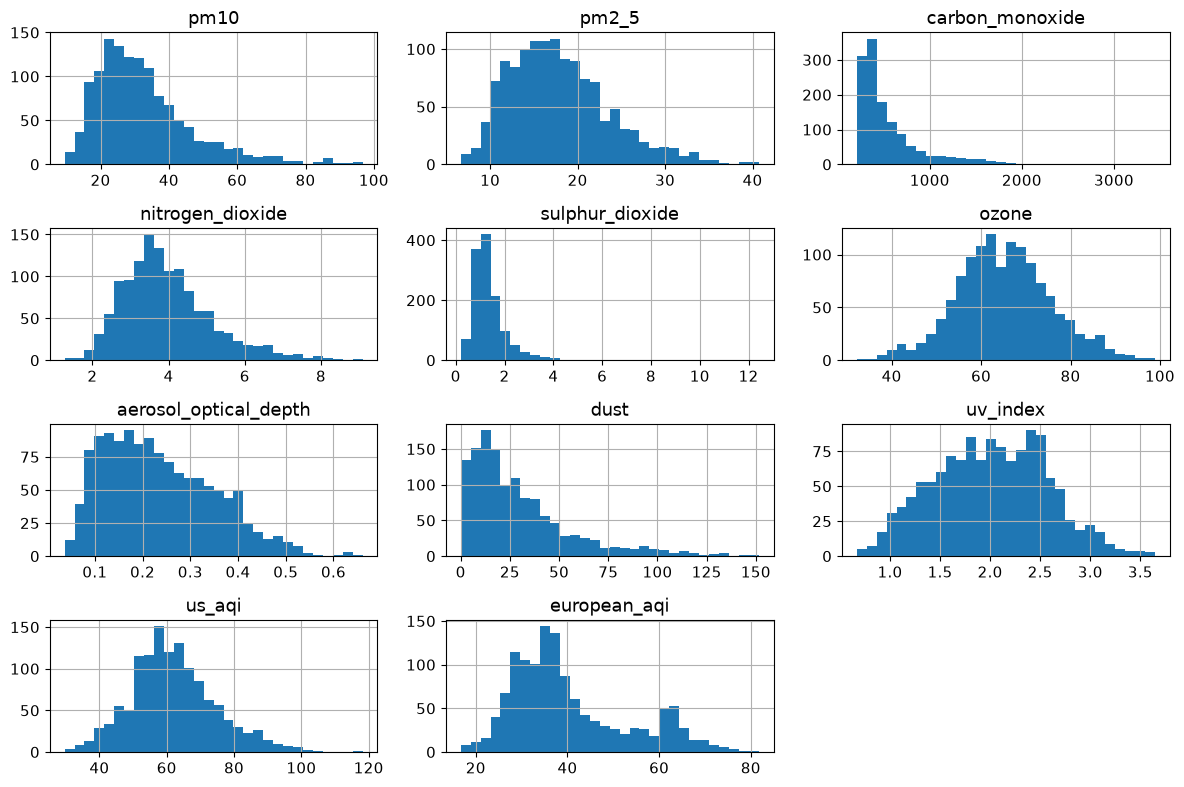

In [9]:
df_clean.select_dtypes(include="number").hist(figsize=(12,8), bins=30)
plt.tight_layout()
plt.savefig(Fig_Dir/"distributions.png")

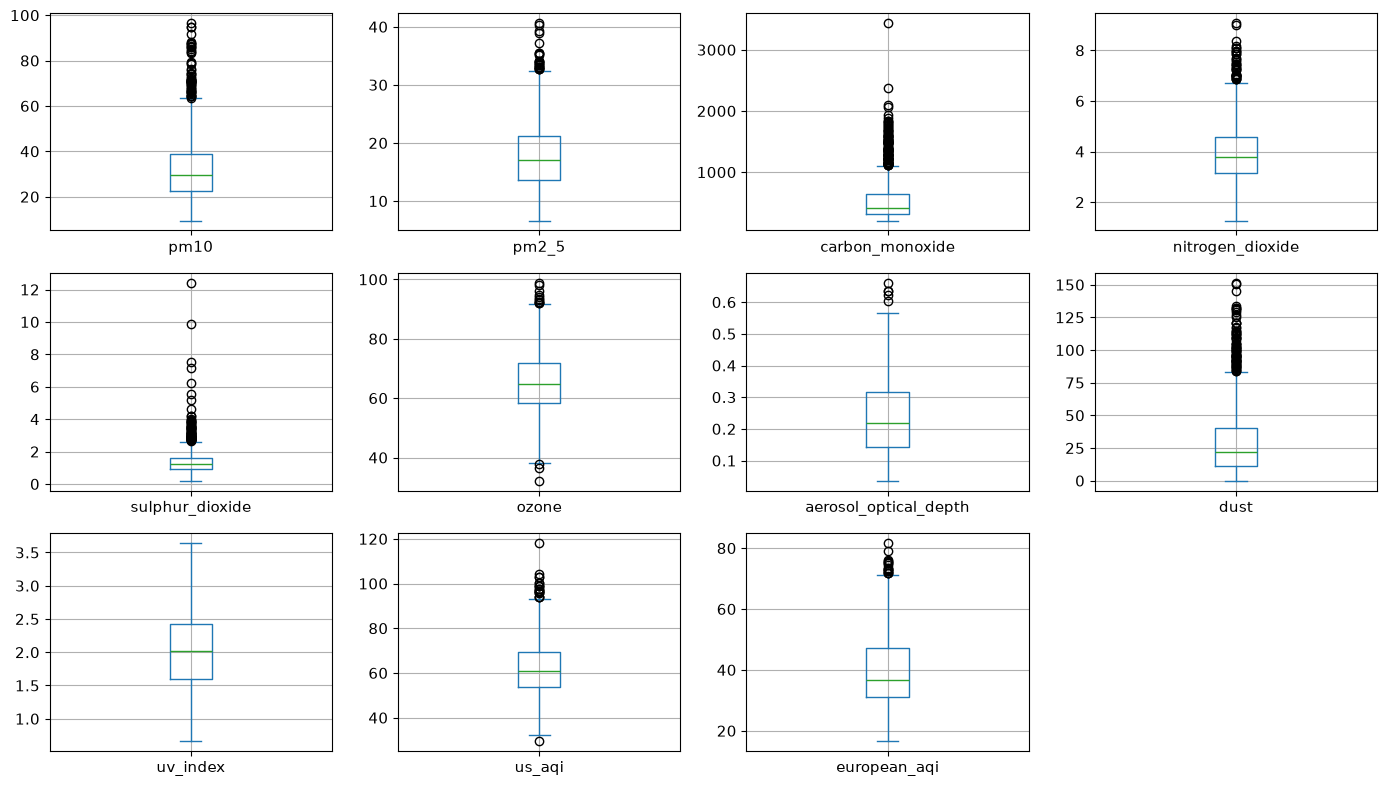

In [10]:
# one panel per column with its own y-axis, so small-valued columns are not flattened by CO
df_clean.select_dtypes(include="number").plot(kind="box", subplots=True, layout=(3, 4), sharey=False, figsize=(14, 8))
plt.tight_layout()
plt.savefig(Fig_Dir/"boxplot.png")

In [11]:
# CO outliers: real events or errors? Check the top days and how they spread over years
print(df_clean.nlargest(5, "carbon_monoxide")[["date", "carbon_monoxide", "pm2_5", "nitrogen_dioxide"]])
print(df_clean.groupby(df_clean["date"].dt.year)["carbon_monoxide"].agg(["mean", "median", "max"]).round(0))

          date  carbon_monoxide      pm2_5  nitrogen_dioxide
229 2023-03-22      3442.625000  37.241667          8.983333
322 2023-06-23      2374.458333  35.525000          5.825000
203 2023-02-24      2105.166667  25.979167          6.154167
230 2023-03-23      2071.708333  35.337500          5.691667
17  2022-08-22      1931.333333  21.466667          5.658333
       mean  median     max
date                       
2022  870.0   828.0  1931.0
2023  642.0   384.0  3443.0
2024  359.0   331.0   963.0
2025  507.0   488.0   970.0
2026  448.0   436.0   674.0


**Findings**
- `pm2_5` (target) is mildly right-skewed: most days 10–25 µg/m³, a thin tail up to ~40.
- `carbon_monoxide`, `sulphur_dioxide`, `dust` and `pm10` are strongly right-skewed; `ozone`, `nitrogen_dioxide` and `uv_index` are roughly symmetric.
- The highest CO days also have high PM2.5 and NO2, so they are real pollution events, not errors, and are kept.
- **All CO outliers fall in 2022–2023**; mean CO drops from ~870 (2022) to ~360 (2024). This is either a real change or a change in the CAMS model. Either way it is a **distribution shift** that a time-based train/test split must account for.

## 6. Time patterns

In [12]:
df_clean["month"] = df_clean["date"].dt.month

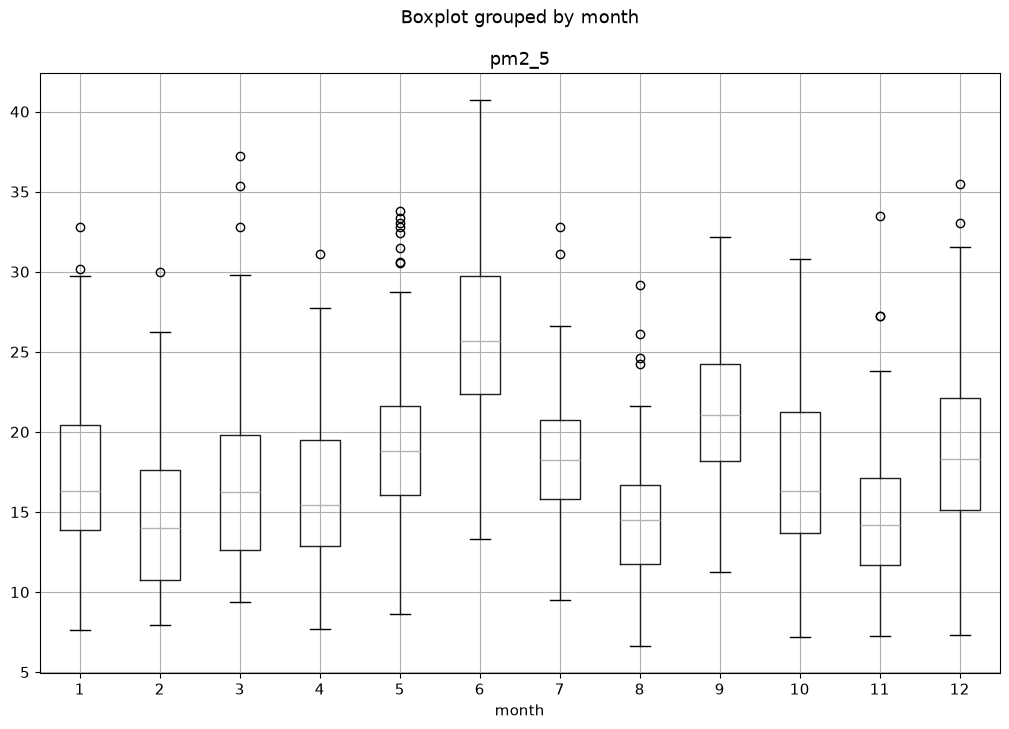

In [13]:
df_clean.boxplot(column="pm2_5", by="month", figsize=(12,8))
plt.savefig(Fig_Dir/"pm25_by_month")

**Findings**
- Clear seasonality: **June** is highest (median ~26 µg/m³) and September second; **February, August and November** are lowest (~14).
- August, the peak of the rainy season, is among the cleanest months (rain washes particles out), while the start and end of the rains are the most polluted.
- Month is therefore a useful feature for modelling.
- A check around Meskel (27 Sept) showed no clear spike.

## 7. Relationships between variables

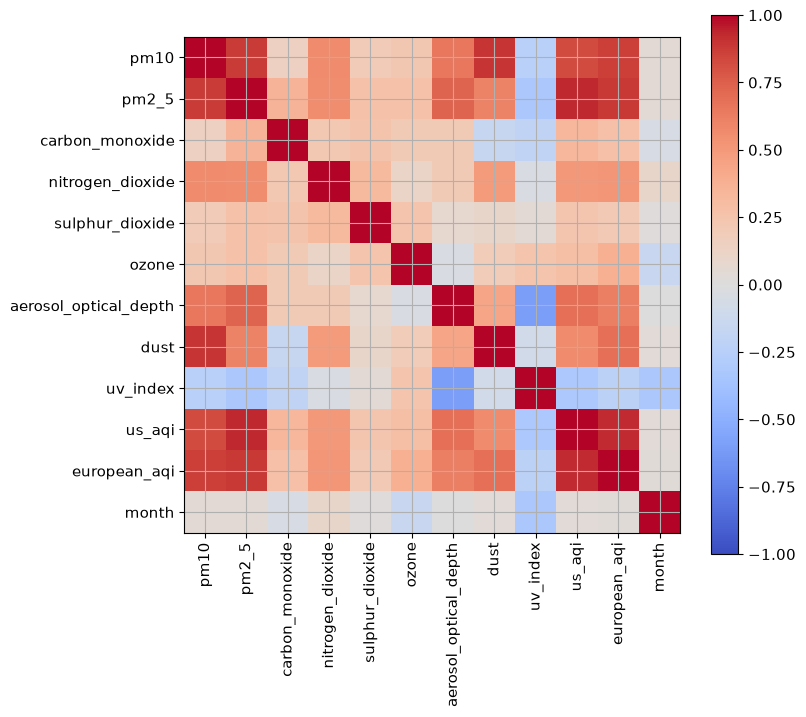

In [14]:
plt.figure(figsize=(8, 7))
# 1. Compute correlation matrix
corr = df_clean.corr(numeric_only=True)

# 2. Plot heatmap
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()

# Add column names to both axes
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)



plt.savefig(Fig_Dir/"correlation")

**Findings** (correlation with `pm2_5`)
- `us_aqi` (0.93) and `european_aqi` (0.88) are calculated from PM2.5, so they are **excluded as features** to avoid target leakage.
- `pm10` (0.88) is very strong because PM10 contains PM2.5. `aerosol_optical_depth` (0.73), `dust` (0.60) and `nitrogen_dioxide` (0.56) are useful signals.
- `uv_index` is negative (−0.32): sunnier days have slightly less PM2.5.
- `month` shows ~0 correlation despite strong seasonality, because correlation only measures straight-line relationships and the seasonal pattern is not linear.

## 8. Summary & next steps

In [15]:
# save the cleaned data for the modelling notebook, then reload to confirm
clean_path = Processed_Dir / "air_quality_clean.csv"
df_clean.to_csv(clean_path, index=False)

check = pd.read_csv(clean_path, parse_dates=["date"])
print(check.shape, check.isna().sum().sum())

(1294, 13) 0


**Summary**
- **Data:** 1,294 consecutive days (2022-08-05 to 2026-02-18) of model-based (CAMS) air quality for Addis Ababa, no missing values after cleaning.
- **Cleaning:** dropped 4 start-up days; interpolated a 2-day source glitch (14–15 Dec 2022).
- **Target:** `pm2_5` is mildly right-skewed (mostly 10–25 µg/m³).
- **Seasonality:** June highest, Feb/Aug/Nov lowest, so month (in a non-linear form) should help the model.
- **Leakage:** `us_aqi` and `european_aqi` are derived from PM2.5 and will be excluded.
- **Distribution shift:** CO levels in 2022–2023 are much higher than later, so the model must be evaluated with a time-based split.

**Next steps:** define the problem framing (forecast vs same-day estimate), split by time, build a baseline, then compare models. The cleaned data is saved to `data/processed/air_quality_clean.csv`.